# ⚽ 什么指标对赢球最关键？— 2022/23 英超 · 西甲 · 欧冠

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/uhonglim/football-win-factors/blob/main/analysis.ipynb)

**问题**：在一场比赛里，哪些技术统计最能决定输赢？

**数据**：ESPN 公开比赛数据，2022/23 赛季
- 抓取：英超 380 场、西甲 375 场、欧冠小组赛起 125 场
- 其中 ESPN 有 108 场技术统计缺失（全部为 0），剔除后用于分析：**英超 293 · 西甲 351 · 欧冠 123 场（另有 6 场因传中/射门为 0 无法计算比率而剔除）**
- 每场比赛拆成两行（主队视角 + 客队视角）
- 稳健性检验：用 football-data.co.uk 的**全部 760 场**联赛（射门、射正、角球、犯规、牌）重复核心结论

**方法**
1. 每个指标都换成 **"本队 − 对手"的差值**（赢球是相对的，射门 15 次在对手射 25 次时并不算多）
2. **单变量**：赢下某项统计"对决"时的胜率；差值与胜利的相关系数
3. **多变量**：标准化 Logistic 回归 + 随机森林置换重要性，交叉验证 AUC
4. **赛季层面**：球队场均数据 vs 场均积分（消除"领先后收缩"带来的比赛状态偏差）

> 进球、助攻、扑救（= 对手射正 − 对手进球，会泄露比分）不作为特征。

In [1]:
import pandas as pd, numpy as np, json, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.inspection import permutation_importance
import matplotlib.font_manager as fm, sys, subprocess
# 中文字体：Colab 上安装 Noto CJK；本地 Mac 用系统自带字体
if "google.colab" in sys.modules and not any("Noto Sans CJK" in f.name for f in fm.fontManager.ttflist):
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True)
    for p in fm.findSystemFonts():
        if "NotoSansCJK" in p: fm.fontManager.addfont(p)
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP", "PingFang SC", "Arial Unicode MS", "Heiti TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

URL = "https://raw.githubusercontent.com/uhonglim/football-win-factors/main/data/matches_2223.csv"
df = pd.read_csv("data/matches_2223.csv") if os.path.exists("data/matches_2223.csv") else pd.read_csv(URL)
# 想重新抓取数据：!python fetch_data.py（见仓库）
print(df.shape)
df.groupby("competition").size().div(2).astype(int).rename("比赛场数")

(1760, 38)


competition
Champions League    125
La Liga             375
Premier League      380
Name: 比赛场数, dtype: int64

## 1. 数据整理：结果、衍生指标、对手差值

In [2]:
# ESPN 有 108 场比赛的技术统计全部为 0（数据缺失，英超 83 / 西甲 23 / 欧冠 2），剔除
missing = df.groupby("event_id").totalPasses.transform("sum") == 0
print("剔除缺失统计的比赛：", (df[missing].groupby("competition").size() // 2).to_dict())
df = df[~missing].copy()

df["result"] = np.select([df.goals > df.goals_against, df.goals < df.goals_against], ["W", "L"], "D")
df["win"] = (df.result == "W").astype(int)
df["points"] = df.result.map({"W": 3, "D": 1, "L": 0})

# 衍生指标（自己计算比 ESPN 四舍五入到一位小数的百分比更精确）
df["shot_accuracy"] = df.shotsOnTarget / df.totalShots.replace(0, np.nan)
df["pass_accuracy"] = df.accuratePasses / df.totalPasses.replace(0, np.nan)
df["cross_accuracy"] = df.accurateCrosses / df.totalCrosses.replace(0, np.nan)
df["tackle_success"] = df.effectiveTackles / df.totalTackles.replace(0, np.nan)
df["long_ball_share"] = df.totalLongBalls / df.totalPasses.replace(0, np.nan)

FEATURES = {
    "shotsOnTarget": "射正次数", "totalShots": "射门次数", "shot_accuracy": "射正率",
    "possessionPct": "控球率", "pass_accuracy": "传球成功率",
    "totalCrosses": "传中次数", "cross_accuracy": "传中成功率", "long_ball_share": "长传占比",
    "wonCorners": "角球", "blockedShots": "封堵射门", "totalTackles": "抢断尝试",
    "tackle_success": "抢断成功率", "interceptions": "拦截", "totalClearance": "解围",
    "foulsCommitted": "犯规", "yellowCards": "黄牌", "redCards": "红牌", "offsides": "越位",
}
F = list(FEATURES)

# 传球次数与控球率相关 0.96，只保留控球率，避免多重共线性
# 对手的同场数据 → 差值
opp = df[["event_id", "team"] + F].rename(columns={"team": "opponent", **{f: f + "_opp" for f in F}})
df = df.merge(opp, on=["event_id", "opponent"])
for f in F:
    df[f + "_diff"] = df[f] - df[f + "_opp"]
D = [f + "_diff" for f in F]
COMPS = ["Premier League", "La Liga", "Champions League"]
CN = {"Premier League": "英超", "La Liga": "西甲", "Champions League": "欧冠"}
df = df.dropna(subset=D).reset_index(drop=True)
print(df.shape)
(df.groupby("competition").result.value_counts(normalize=True).unstack()[["W", "D", "L"]] * 100).round(1)

剔除缺失统计的比赛： {'Champions League': 2, 'La Liga': 23, 'Premier League': 83}
(1534, 82)


result,W,D,L
competition,,,
Champions League,39.8,20.3,39.8
La Liga,37.7,24.5,37.7
Premier League,38.6,22.9,38.6


## 2. 单变量：赢下哪项"统计对决"最能带来胜利？

对每一项指标，看一支球队在这项上**多于对手**时的胜率。基准胜率约 37%（三种结果里有平局）。

In [3]:
def battle_table(d):
    rows = []
    for f in F:
        more = d[d[f + "_diff"] > 0]; less = d[d[f + "_diff"] < 0]
        rows.append({"feature": f, "指标": FEATURES[f],
                     "领先时胜率": more.win.mean(), "落后时胜率": less.win.mean(),
                     "领先时场均积分": more.points.mean(),
                     "相关系数r(差值,胜)": d[f + "_diff"].corr(d.win),
                     "相关系数r(差值,净胜球)": d[f + "_diff"].corr(d.goals - d.goals_against)})
    return pd.DataFrame(rows).sort_values("相关系数r(差值,胜)", key=abs, ascending=False)

battle = {c: battle_table(df[df.competition == c]) for c in COMPS}
battle["全部"] = battle_table(df)
battle["全部"].style.format({c: "{:.3f}" for c in battle["全部"].columns[2:]}).background_gradient(subset=["相关系数r(差值,胜)"], cmap="RdBu", vmin=-.5, vmax=.5)

,feature,指标,领先时胜率,落后时胜率,领先时场均积分,"相关系数r(差值,胜)","相关系数r(差值,净胜球)"
0,shotsOnTarget,射正次数,0.629,0.139,2.120,0.495,0.655
2,shot_accuracy,射正率,0.537,0.233,1.842,0.325,0.404
1,totalShots,射门次数,0.512,0.254,1.770,0.316,0.422
16,redCards,红牌,0.132,0.581,0.682,-0.183,-0.202
5,totalCrosses,传中次数,0.325,0.448,1.201,-0.144,-0.091
3,possessionPct,控球率,0.430,0.337,1.523,0.121,0.228
13,totalClearance,解围,0.438,0.329,1.546,0.117,0.036
4,pass_accuracy,传球成功率,0.443,0.325,1.562,0.108,0.201
9,blockedShots,封堵射门,0.424,0.346,1.501,0.099,0.155
6,cross_accuracy,传中成功率,0.404,0.365,1.442,0.089,0.093


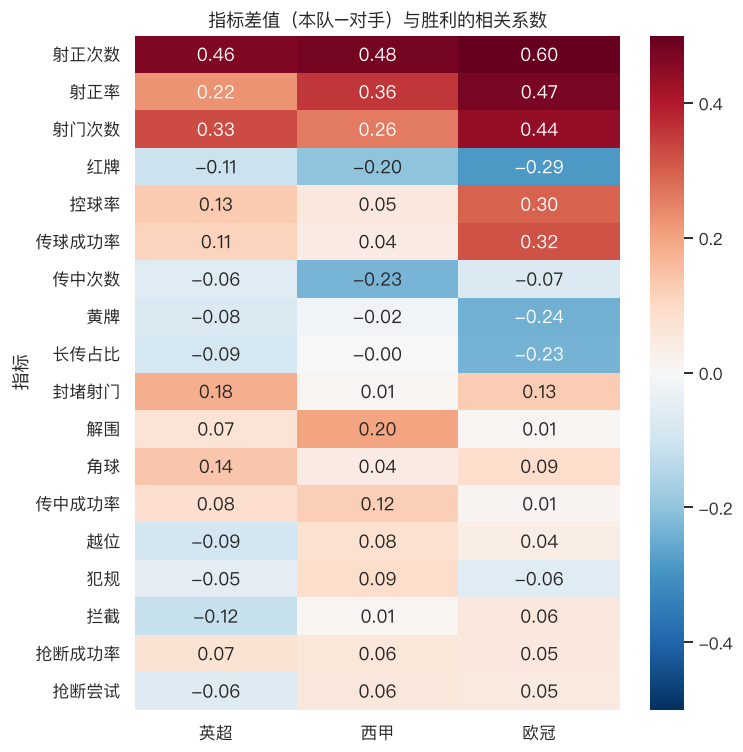

In [4]:
corr = pd.DataFrame({CN[c]: battle[c].set_index("指标")["相关系数r(差值,胜)"] for c in COMPS})
corr = corr.loc[corr.abs().mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.5, vmax=.5, ax=ax)
ax.set_title("指标差值（本队−对手）与胜利的相关系数")
plt.tight_layout(); plt.show()

**观察**
- **射正差值遥遥领先**：与胜利的相关系数 英超 0.46 / 西甲 0.48 / 欧冠 0.60，射正多于对手时胜率 61%–73%。
- 第二梯队是**射正率**和**射门次数**（r≈0.3）。
- **控球率在联赛里几乎无关**（英超 0.13、西甲 0.05），控球占优时胜率只有 38%–46%；但在**欧冠相关更强（0.30）**——欧冠强弱分明，控球更能反映实力差。
- **传中越多越难赢**（r 为负，传中占优时胜率仅 33%）：大量传中往往是落后方在"往禁区里砸"。
- **红牌**是最稳定的负面因素。

## 3. 多变量模型：控制其它指标后，谁的独立贡献最大？

In [5]:
def fit_models(d, feats):
    X, y = d[feats].values, d.win.values
    cv = StratifiedKFold(5, shuffle=True, random_state=42)
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
    auc_lr = cross_val_score(lr, X, y, cv=cv, scoring="roc_auc").mean()
    lr.fit(X, y)
    coef = pd.Series(lr[-1].coef_[0], index=feats)
    rf = RandomForestClassifier(400, min_samples_leaf=10, random_state=42, n_jobs=-1)
    auc_rf = cross_val_score(rf, X, y, cv=cv, scoring="roc_auc").mean()
    rf.fit(X, y)
    pi = permutation_importance(rf, X, y, n_repeats=10, random_state=42, scoring="roc_auc")
    imp = pd.Series(pi.importances_mean, index=feats)
    return dict(auc_lr=auc_lr, auc_rf=auc_rf, coef=coef, imp=imp)

models = {c: fit_models(df[df.competition == c], D) for c in COMPS}
models["全部"] = fit_models(df, D)
pd.DataFrame({k: {"Logistic AUC": v["auc_lr"], "随机森林 AUC": v["auc_rf"]} for k, v in models.items()}).round(3)

,Premier League,La Liga,Champions League,全部
Logistic AUC,0.822,0.884,0.913,0.871
随机森林 AUC,0.802,0.853,0.868,0.851


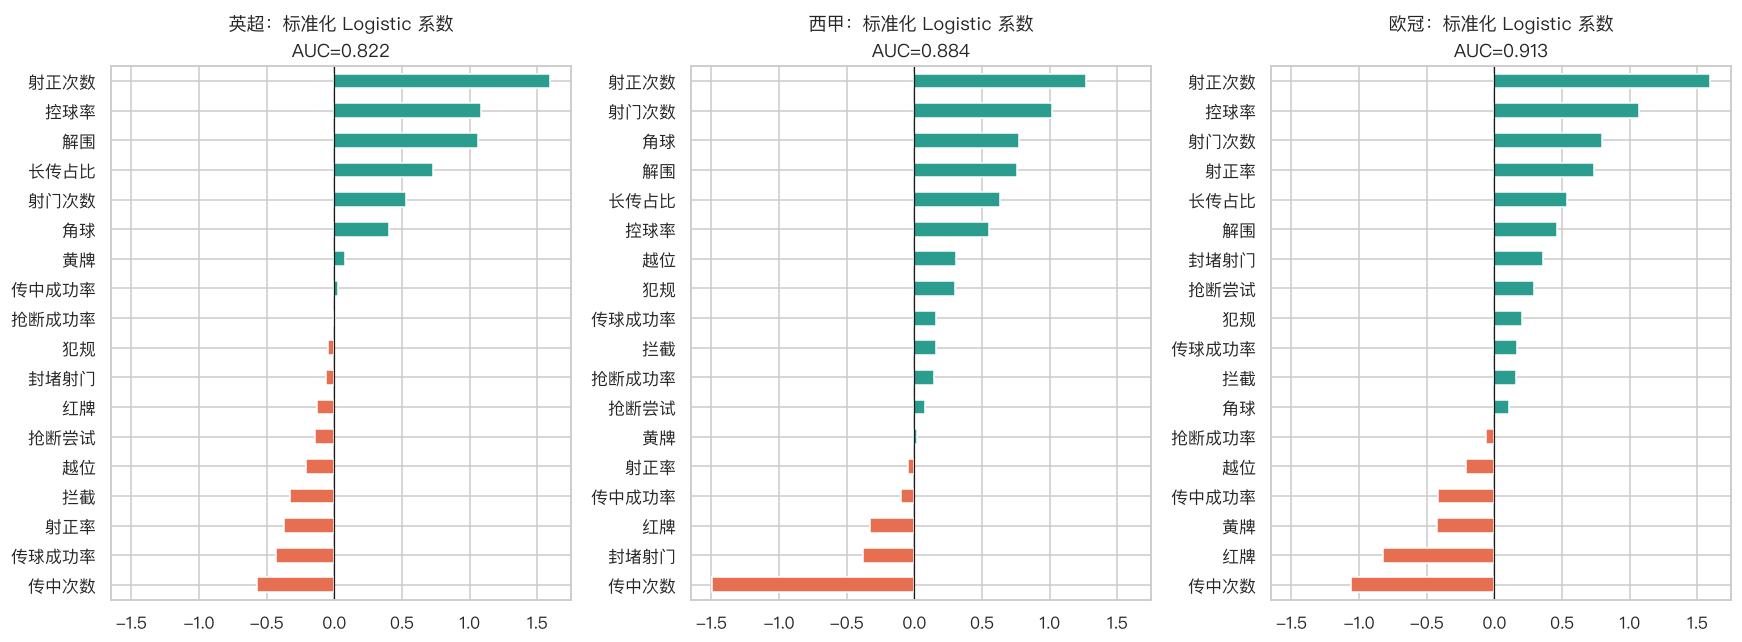

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharex=True)
for ax, c in zip(axes, COMPS):
    s = models[c]["coef"].rename(lambda x: FEATURES[x[:-5]]).sort_values()
    s.plot.barh(ax=ax, color=np.where(s > 0, "#2a9d8f", "#e76f51"))
    ax.set_title(f"{CN[c]}：标准化 Logistic 系数\nAUC={models[c]['auc_lr']:.3f}")
    ax.axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.show()

**解读**：系数 = 该指标差值增加 1 个标准差时，赢球对数几率的变化（其它指标不变）。

- **射正**在三项赛事里都是最大的正系数；随机森林置换重要性里，射正（≈0.14）是第二名的 2–4 倍。
- **控球率**在控制了射门之后变成了正贡献（系数≈+1）：射门一样多时，控球更多的一方更容易赢。
- **传中次数**是最大的负系数：落后方会大量传中，所以"传中多"是落后的信号。
- **解围、长传占比**为正：领先后收缩防守、开大脚——这是比分影响数据，而不是数据造就比分。
- **红牌**在三项赛事里都是负的，欧冠最明显。
- 只用技术统计（不含进球）就能达到 AUC 0.82–0.91。

## 4. 去掉射门指标：比赛"过程"里什么最重要？

射正和进球几乎是同一件事。去掉射门/射正/射正率，看哪些**过程指标**还能预测胜负。

In [7]:
SHOOT = {"shotsOnTarget_diff", "totalShots_diff", "shot_accuracy_diff", "blockedShots_diff"}
P = [f for f in D if f not in SHOOT]
proc = {c: fit_models(df[df.competition == c], P) for c in COMPS}
proc["全部"] = fit_models(df, P)
print({k: round(v["auc_lr"], 3) for k, v in proc.items()})
pd.DataFrame({CN.get(k, k): v["coef"].rename(lambda x: FEATURES[x[:-5]]) for k, v in proc.items()}).sort_values("全部").round(2)

{'Premier League': np.float64(0.71), 'La Liga': np.float64(0.794), 'Champions League': np.float64(0.803), '全部': np.float64(0.77)}


,英超,西甲,欧冠,全部
传中次数,-0.72,-1.47,-1.36,-1.24
红牌,-0.22,-0.53,-0.82,-0.47
黄牌,-0.16,-0.16,-0.75,-0.24
拦截,-0.14,0.04,0.17,0.00
越位,-0.20,0.32,0.08,0.08
传中成功率,0.14,0.17,0.12,0.13
抢断尝试,-0.01,0.18,0.36,0.14
抢断成功率,0.20,0.14,0.11,0.14
犯规,0.01,0.35,0.37,0.21
解围,0.75,0.47,0.38,0.43


去掉射门后 AUC 从 0.87 降到 0.77——射门是赢球的"最后一公里"。
剩下的过程指标里，**角球、控球率、长传占比、解围**为正，**传中次数、红牌**为负。
其中"解围多、传中少"更多反映的是**比赛状态**（领先方在防守，落后方在传中），因果方向是反的。
要过滤这种偏差，下一步看**整个赛季**。

## 5. 赛季层面：长期来看，哪些数据造就积分榜高位？

单场数据会被比分牵着走（领先 → 收缩）。赛季平均可以过滤掉这种噪音：
把每支队 38 轮的**场均差值**和**场均积分**做相关（英超 20 队 + 西甲 20 队）。

In [8]:
lg = df[df.competition != "Champions League"]
team = lg.groupby(["competition", "team"]).agg(ppg=("points", "mean"), gd=("goals", "mean"), ga=("goals_against", "mean"),
                                              **{f: (f, "mean") for f in D})
season_corr = pd.DataFrame({
    "英超": team.loc["Premier League"][D].corrwith(team.loc["Premier League"].ppg),
    "西甲": team.loc["La Liga"][D].corrwith(team.loc["La Liga"].ppg),
    "两联赛合并": team[D].corrwith(team.ppg)}).rename(lambda x: FEATURES[x[:-5]])
season_corr.sort_values("两联赛合并", ascending=False).round(2)

,英超,西甲,两联赛合并
射正次数,0.78,0.88,0.82
射门次数,0.71,0.77,0.73
控球率,0.63,0.76,0.68
传球成功率,0.62,0.71,0.65
封堵射门,0.57,0.58,0.57
角球,0.54,0.58,0.56
抢断成功率,0.16,0.62,0.37
传中次数,0.46,0.09,0.31
射正率,0.14,0.37,0.23
传中成功率,0.12,-0.06,0.05


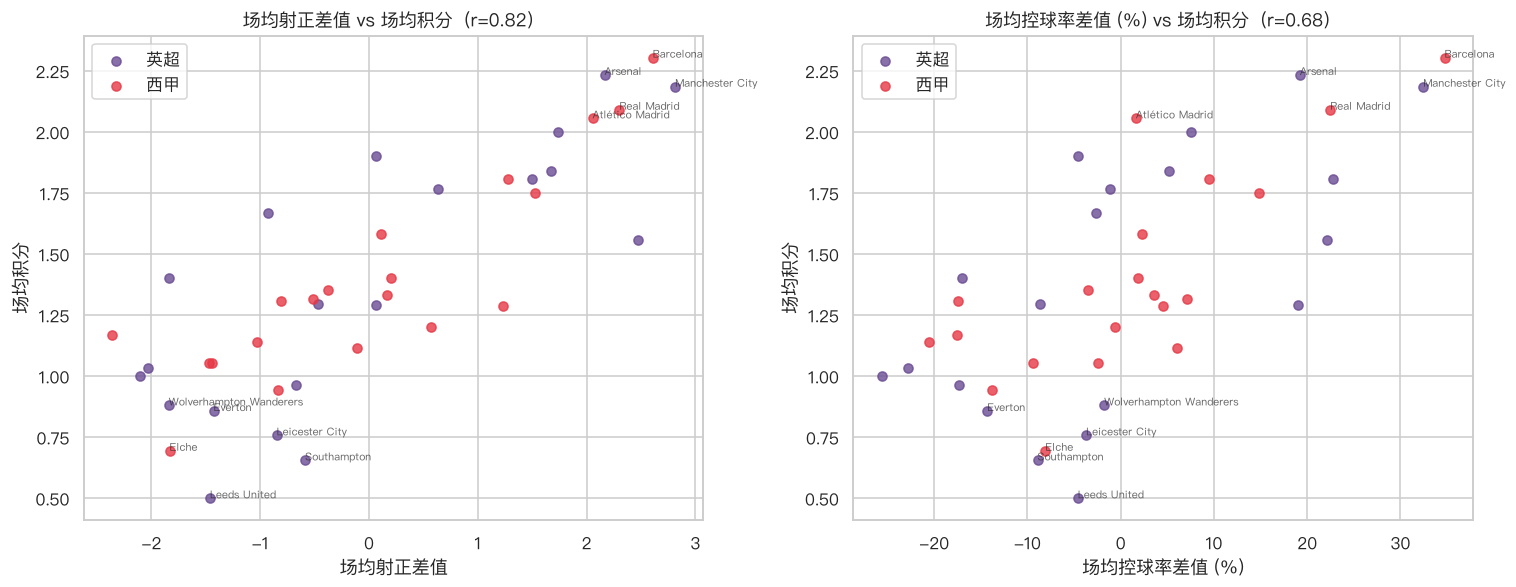

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (x, label) in zip(axes, [("shotsOnTarget_diff", "场均射正差值"), ("possessionPct_diff", "场均控球率差值 (%)")]):
    for c, col in [("Premier League", "#6a4c93"), ("La Liga", "#e63946")]:
        t = team.loc[c]
        ax.scatter(t[x], t.ppg, label=CN[c], color=col, alpha=.8)
        for name, r in t.iterrows():
            if r.ppg > 2.0 or r.ppg < .9: ax.annotate(name, (r[x], r.ppg), fontsize=7, alpha=.7)
    ax.set_xlabel(label); ax.set_ylabel("场均积分"); ax.legend()
    ax.set_title(f"{label} vs 场均积分（r={team[x].corr(team.ppg):.2f}）")
plt.tight_layout(); plt.show()

**关键反转**：单场里控球率与胜利的相关只有 0.12（三项赛事合计），但在**赛季层面控球率差值与场均积分的相关达到 0.68**。
强队整个赛季都控球更多，只是在具体某场领先后会让出球权。
- 赛季层面最强的仍然是**射正差值（r=0.82）**，其次射门（0.73）、控球（0.68）、传球成功率（0.65）。
- **拦截（−0.66）、长传占比（−0.63）、抢断尝试（−0.51）、解围（−0.48）**为负：弱队整季都在防守、开大脚。

所以：**控球是"强队的标志"，射正是"赢下这一场的方式"。**

## 6. 主场优势 & 三项赛事对比

In [10]:
home = df.groupby(["competition", "home"]).win.mean().unstack().rename(columns={0: "客场胜率", 1: "主场胜率"})
home["主场加成(百分点)"] = (home["主场胜率"] - home["客场胜率"]) * 100
home.round(3)

home,客场胜率,主场胜率,主场加成(百分点)
competition,,,
Champions League,0.301,0.496,19.512
La Liga,0.276,0.479,20.228
Premier League,0.290,0.481,19.113


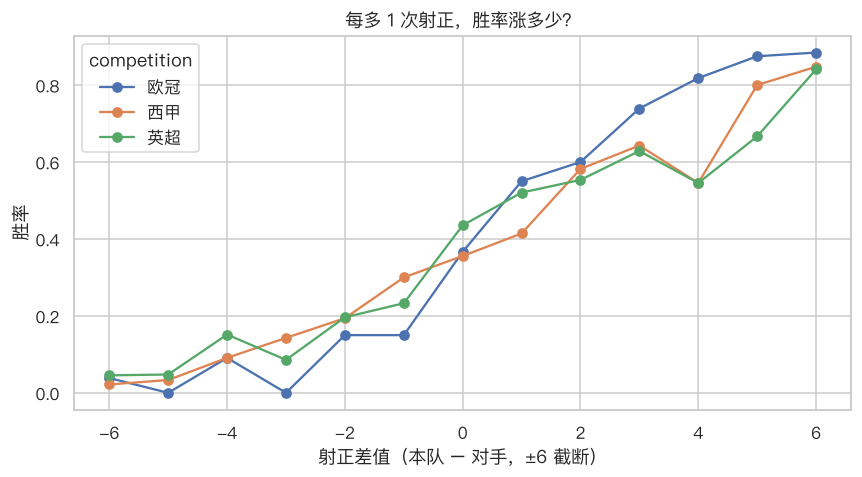

competition,Champions League,La Liga,Premier League
sot_bin,,,
-6.0,0.04,0.02,0.05
-5.0,0.00,0.03,0.05
-4.0,0.09,0.09,0.15
-3.0,0.00,0.14,0.09
-2.0,0.15,0.19,0.20
-1.0,0.15,0.30,0.23
0.0,0.37,0.36,0.44
1.0,0.55,0.41,0.52
2.0,0.60,0.58,0.55


In [11]:
# 射正"对决"：多射正 N 个时的胜率曲线
df["sot_bin"] = df.shotsOnTarget_diff.clip(-6, 6)
curve = df.groupby(["competition", "sot_bin"]).win.mean().unstack(0)
ax = curve.rename(columns=CN).plot(marker="o", figsize=(8, 4.5))
ax.set_xlabel("射正差值（本队 − 对手，±6 截断）"); ax.set_ylabel("胜率"); ax.set_title("每多 1 次射正，胜率涨多少？")
plt.tight_layout(); plt.show()
curve.round(2)

## 7. 稳健性检验：football-data.co.uk 全部 760 场联赛

ESPN 缺了一些比赛。换一个独立数据源（覆盖英超、西甲全部 380 场，但只有射门、射正、角球、犯规、黄红牌），重复单变量检验。

In [12]:
FD = {"英超": "fd_E0_2223.csv", "西甲": "fd_SP1_2223.csv"}
fd_rows = []
for lgname, fn in FD.items():
    path = f"data/{fn}" if os.path.exists(f"data/{fn}") else URL.replace("matches_2223.csv", fn)
    m = pd.read_csv(path)
    for side, o in [("H", "A"), ("A", "H")]:
        t = pd.DataFrame({"联赛": lgname,
            "win": ((m.FTHG > m.FTAG) if side == "H" else (m.FTAG > m.FTHG)).astype(int),
            "射正次数": m[side + "ST"] - m[o + "ST"], "射门次数": m[side + "S"] - m[o + "S"],
            "角球": m[side + "C"] - m[o + "C"], "犯规": m[side + "F"] - m[o + "F"],
            "黄牌": m[side + "Y"] - m[o + "Y"], "红牌": m[side + "R"] - m[o + "R"]})
        fd_rows.append(t)
fd = pd.concat(fd_rows)
fd_corr = pd.DataFrame({lgname: g.drop(columns=["联赛", "win"]).corrwith(g.win) for lgname, g in fd.groupby("联赛")})
espn_corr = corr.loc[fd_corr.index, ["英超", "西甲"]]
robust = pd.concat({"football-data (380场)": fd_corr, "ESPN (本分析)": espn_corr}, axis=1)
print("场次：", fd.groupby("联赛").size().div(2).to_dict())
robust.round(3)

场次： {'英超': 380.0, '西甲': 380.0}


football-data (380场)        ESPN (本分析)       
                       英超     西甲         英超     西甲
射正次数                0.478  0.472      0.464  0.480
射门次数                0.309  0.243      0.326  0.259
角球                  0.133  0.031      0.141  0.041
犯规                 -0.029  0.080     -0.054  0.091
黄牌                 -0.092 -0.021     -0.078 -0.017
红牌                 -0.100 -0.215     -0.108 -0.199

两个数据源的相关系数几乎一致 → ESPN 缺失的比赛不影响结论。

## 8. 导出结果（供网站使用）

In [13]:
def ser(s): return {k: (None if pd.isna(v) else round(float(v), 4)) for k, v in s.items()}
out = {
    "meta": {"matches": {CN[c]: int((df.competition == c).sum() // 2) for c in COMPS}, "rows": int(len(df)),
             "results": {CN[c]: ser(df[df.competition == c].result.value_counts(normalize=True)) for c in COMPS}},
    "features": FEATURES,
    "battle": {CN.get(k, k): v.drop(columns="指标").set_index("feature").round(4).to_dict(orient="index") for k, v in battle.items()},
    "models": {CN.get(k, k): {"auc_lr": round(v["auc_lr"], 4), "auc_rf": round(v["auc_rf"], 4),
                              "coef": ser(v["coef"].rename(lambda x: x[:-5])), "imp": ser(v["imp"].rename(lambda x: x[:-5]))}
               for k, v in models.items()},
    "process_models": {CN.get(k, k): {"auc_lr": round(v["auc_lr"], 4), "coef": ser(v["coef"].rename(lambda x: x[:-5]))} for k, v in proc.items()},
    "season_corr": {k: ser(team.loc[c][D].corrwith(team.loc[c].ppg).rename(lambda x: x[:-5])) for k, c in [("英超", "Premier League"), ("西甲", "La Liga")]},
    "season_corr_pooled": ser(team[D].corrwith(team.ppg).rename(lambda x: x[:-5])),
    "season_teams": {CN[c]: [{"team": n, "ppg": round(r.ppg, 3), "sot": round(r.shotsOnTarget_diff, 3), "pos": round(r.possessionPct_diff, 3)}
                             for n, r in team.loc[c].iterrows()] for c in ["Premier League", "La Liga"]},
    "sot_curve": {CN[c]: ser(curve[c].rename(lambda x: str(int(x)))) for c in COMPS},
    "home": {CN[c]: ser(home.loc[c]) for c in COMPS},
    "robust": {f"{a}|{b}": ser(robust[(a, b)]) for a, b in robust.columns},
}
os.makedirs("docs", exist_ok=True)
json.dump(out, open("docs/results.json", "w"), ensure_ascii=False, indent=1)
print("saved docs/results.json")

saved docs/results.json


## 9. 结论

1. **射正是赢球第一指标。** 单场相关 0.46–0.60、赛季相关 0.82，模型重要性是第二名的 2–4 倍。射正比对手多 3 次，胜率 63%–74%；多 6 次以上，胜率超过 84%。
2. **射正 > 射门。** 射门次数（r≈0.3）远不如射正（r≈0.5），射正率本身也有用——质量比数量重要。
3. **控球是"强队标志"，不是"赢球按钮"。** 单场控球与胜负相关只有 0.12（三项赛事合计；英超 0.13、西甲 0.05），领先方常主动让出球权；但赛季层面控球与积分相关 0.68。欧冠里单场控球更重要（0.30）。
4. **防守和传中数据要反着读。** 解围多、长传多常意味着在保护领先；传中多常意味着在追分。
5. **纪律很重要。** 红牌在三项赛事里都是负面因素，欧冠最明显（r=−0.29）。
6. **主场优势约 19–20 个百分点**（主场胜率约 48%–50%，客场 28%–30%），三项赛事几乎一样。
7. **三项赛事结论一致**，欧冠由于强弱差距大，技术统计对胜负的解释力最高（AUC 0.91）。

*局限*：技术统计和比分互相影响（相关≠因果）；没有 xG 数据；ESPN 缺失 108 场统计（已用 football-data 全量数据验证不影响核心结论）；欧冠淘汰赛加时进球计入比分、点球大战按平局处理。